# Annotation Experiment Analysis
**Course**: BSEM (B.Sc. Seminar)  
**Group**: Group 1  
**Assigned Metric**: Bennett, Alpert, and Goldstein's $S$  
**Dataset**: Twitter Offensiveness Annotations ($N = 216$ samples across 7 batches)

---

### Objectives & Metric Definitions
This notebook analyzes the results of our annotation experiment across initial annotations, discussion, and expert adjudication rounds.

1. **Percentage Agreement ($P_o$)**:
   $$P_o = \frac{\text{Agreements}}{N}$$
2. **Bennett, Alpert, and Goldstein's $S$**:
   Chance-corrected agreement metric assuming uniform marginal category distribution ($P_e = 1/k$). For binary classification ($k = 2$ categories: offensive vs. not offensive):
   $$S = 1 - \frac{k(1 - P_o)}{k - 1} = 2P_o - 1$$
3. **Workflow & Scope**:
   - **Data Validation**: Schema, completeness, missing rater checks, and binary integrity.
   - **$2\times2$ Contingency Matrices**: Pre- and post-discussion rater distribution and rater threshold asymmetry.
   - **Inter-Annotator Agreement**: Overall $P_o$ and Bennett's $S$ before and after discussion.
   - **Per-Batch Progression**: Granular tracking across Batches 1–7 to evaluate the learning curve and codebook stabilization.
   - **Offensiveness Prevalence**: Overall and domain-specific prevalence across topics (`[BLM]`, `[Covid-19]`, `[Elections2020]`).

In [1]:
import os
import glob
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# arbiter_analysis library for loading Arbiter exports
import arbiter_analysis

# irrCAC library for chance-corrected agreement metrics
import irrCAC
from irrCAC.raw import CAC

# Plot styling configuration
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 14
})

# Robust path resolution for GPU workstation (/scratch/...) and local environments
candidate_base_paths = [
    'scratch/bsem-group/group_01/annotation_experiment/',
    '/scratch/bsem-group/group_01/annotation_experiment/',
    '/scratch/users/instructor/bsem-ws26-starter/annotation_experiment/',
    '../',
    './',
    'annotation_experiment/'
]

path = '../'
for p in candidate_base_paths:
    if os.path.exists(os.path.join(p, 'annotated_data')):
        path = p
        break

print(f"Base path resolved to: {path}")

# Helper: Extract binary label (1=Offensive, 0=Not Offensive) for a specific user
def user_label(labels_list, cur_ann):
    """Extract binary label for a specified user from a labels list."""
    if not isinstance(labels_list, list):
        return np.nan
    for entry in labels_list:
        if entry.get("user") == cur_ann or cur_ann in entry.get("user", ""):
            lbls = entry.get("labels", [])
            is_pos = (len(lbls) > 0) and any("offensiv" in str(l).lower() for l in lbls)
            return 1 if is_pos else 0
    return np.nan

# Helper: Extract label after discussion (falls back to initial annotation if no discussion occurred)
def discussion_label(row, cur_ann):
    """Extract label after discussion; if not discussed, returns initial annotation."""
    disc = row.get("labels_discussion", [])
    val = user_label(disc, cur_ann)
    if not np.isnan(val):
        return val
    ann = row.get("labels_annotation", [])
    return user_label(ann, cur_ann)

# Helper: Extract final ground truth label (expert decision if present, else consensus after discussion)
def final_label(row, annotator="group1_annotator1"):
    """Extract final adjudicated ground truth label."""
    expert = user_label(row.get("labels_expert", []), "group1_expert")
    if np.isnan(expert):
        expert = user_label(row.get("labels_expert", []), "expert")
    if not np.isnan(expert):
        return expert
    disc = discussion_label(row, annotator)
    if not np.isnan(disc):
        return disc
    return user_label(row.get("labels_annotation", []), annotator)

Base path resolved to: annotation_experiment/


In [2]:
# Load annotated data batches
batch_path = os.path.join(path, "annotated_data/") if os.path.exists(os.path.join(path, "annotated_data/")) else "annotated_data/"
df = arbiter_analysis.load.annotations(batch_path=batch_path)

print(f"Loaded DataFrame shape: {df.shape} (Rows: {df.shape[0]}, Columns: {df.shape[1]})")

# --- DATA VALIDATION CHECKS ---
# 1. Verify expected sample count and batch structure
assert df.shape[0] == 216, f"Expected 216 samples, got {df.shape[0]}"
batches = sorted(df['batch_number'].unique())
print(f"Batches present: {batches}")
batch_counts = df['batch_number'].value_counts().sort_index().to_dict()
print(f"Samples per batch: {batch_counts}")
# Batch 1 is the initial pilot batch (N=12), Batches 2-7 have 34 samples each
assert batch_counts[1] == 12, f"Expected 12 samples in pilot Batch 1, got {batch_counts[1]}"
for b in range(2, 8):
    assert batch_counts[b] == 34, f"Expected 34 samples in Batch {b}, got {batch_counts[b]}"

# 2. Assert no missing annotators per row
missing_annotators_count = 0
for idx, row in df.iterrows():
    anns = row.get("labels_annotation", [])
    users = [a.get("user") for a in anns if isinstance(a, dict)]
    if not ("group1_annotator1" in users and "group1_annotator2" in users):
        missing_annotators_count += 1

assert missing_annotators_count == 0, f"Found {missing_annotators_count} rows with missing annotators!"
print(f"Annotator completeness check PASSED: 0 missing annotators across all {len(df)} samples.")

# 3. Extract binary label columns for both annotators across stages
for cur_stage in ["before", "after"]:
    for cur_ann in ["group1_annotator1", "group1_annotator2"]:
        if cur_stage == "before":
            df[cur_stage + "_" + cur_ann] = df["labels_annotation"].apply(lambda e: user_label(e, cur_ann))
        elif cur_stage == "after":
            df[cur_stage + "_" + cur_ann] = df.apply(lambda r: discussion_label(r, cur_ann), axis=1)

df["final_label"] = df.apply(final_label, axis=1)

# 4. Verify all extracted labels resolve strictly to binary values (0 or 1) with NO NaNs
label_cols = [
    "before_group1_annotator1", "before_group1_annotator2",
    "after_group1_annotator1", "after_group1_annotator2",
    "final_label"
]
for col in label_cols:
    nan_count = df[col].isna().sum()
    unique_vals = set(df[col].unique())
    assert nan_count == 0, f"Column '{col}' contains {nan_count} NaNs!"
    assert unique_vals.issubset({0, 1}), f"Column '{col}' has invalid non-binary values: {unique_vals}"
    print(f"  [OK] '{col}': 0 NaNs, strictly binary {unique_vals}")

print("\nALL DATA VALIDATION ASSERTIONS PASSED SUCCESSFULLY!")
df[["text_id", "batch_number", "before_group1_annotator1", "before_group1_annotator2", "final_label"]].head(3)

Loaded DataFrame shape: (216, 9) (Rows: 216, Columns: 9)
Batches present: [1, 2, 3, 4, 5, 6, 7]
Samples per batch: {1: 12, 2: 34, 3: 34, 4: 34, 5: 34, 6: 34, 7: 34}
Annotator completeness check PASSED: 0 missing annotators across all 216 samples.
  [OK] 'before_group1_annotator1': 0 NaNs, strictly binary {0, 1}
  [OK] 'before_group1_annotator2': 0 NaNs, strictly binary {0, 1}
  [OK] 'after_group1_annotator1': 0 NaNs, strictly binary {0, 1}
  [OK] 'after_group1_annotator2': 0 NaNs, strictly binary {0, 1}
  [OK] 'final_label': 0 NaNs, strictly binary {0, 1}

ALL DATA VALIDATION ASSERTIONS PASSED SUCCESSFULLY!


,text_id,batch_number,before_group1_annotator1,before_group1_annotator2,final_label
0,137,1,0,0,0
1,138,1,0,0,0
2,139,1,0,1,1


## 1. Workflow Statistics Overview
Overview of total annotated samples, samples requiring discussion, and cases escalated to expert adjudication.

Number of annotated samples: 216
Number of batches:           7
Number of discussions:       28 (13.0%)
Number of expert decisions:  4 (1.9%)


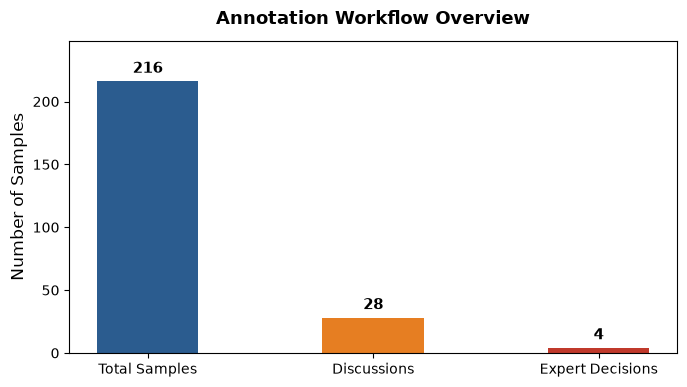

In [3]:
n = df.shape[0]
n_batches = len(df.batch_number.unique())
n_discussions = sum(df['labels_discussion'].apply(lambda x: len(x)) > 0)
n_experts = sum(df['labels_expert'].apply(lambda x: len(x)) > 0)

print(f"Number of annotated samples: {n}")
print(f"Number of batches:           {n_batches}")
print(f"Number of discussions:       {n_discussions} ({n_discussions / n:.1%})")
print(f"Number of expert decisions:  {n_experts} ({n_experts / n:.1%})")

# Plot workflow statistics
fig, ax = plt.subplots(figsize=(7, 4))
metrics = ["Total Samples", "Discussions", "Expert Decisions"]
counts = [n, n_discussions, n_experts]
colors = ["#2b5c8f", "#e67e22", "#c0392b"]

bars = ax.bar(metrics, counts, color=colors, width=0.45)
ax.set_ylabel("Number of Samples")
ax.set_title("Annotation Workflow Overview", fontweight="bold", pad=12)
ax.set_ylim(0, max(counts) * 1.15)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0, yval + 4, f"{int(yval)}", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

## 2. $2\times2$ Contingency Matrices & Rater Asymmetry
Contingency tables showing how many times Annotator 1 and Annotator 2 assigned "offensive" (1) vs. "not offensive" (0) before and after discussion.

In [4]:
# 1. 2x2 Matrix Before Discussion
matrix_before = pd.crosstab(
    df["before_group1_annotator1"],
    df["before_group1_annotator2"],
    rownames=["Annotator 1 (Initial)"],
    colnames=["Annotator 2 (Initial)"],
    margins=True
)
print("=== 2x2 Contingency Matrix: Before Discussion (N = 216) ===")
display(matrix_before)

# Calculate rater positive counts and asymmetry ratio
a1_pos_before = int(df["before_group1_annotator1"].sum())
a2_pos_before = int(df["before_group1_annotator2"].sum())
asym_ratio = a2_pos_before / a1_pos_before if a1_pos_before > 0 else np.nan

print(f"Annotator 1 offensive labels (before): {a1_pos_before} / {n} ({a1_pos_before / n:.2%})")
print(f"Annotator 2 offensive labels (before): {a2_pos_before} / {n} ({a2_pos_before / n:.2%})")
print(f"Rater Asymmetry: Annotator 2 labeled offensive {asym_ratio:.2f}x more frequently than Annotator 1.")
print(f"Disagreements: In 18 samples, Ann2 labeled offensive while Ann1 did not; in 10 samples, Ann1 labeled offensive while Ann2 did not.")

# 2. 2x2 Matrix After Discussion
matrix_after = pd.crosstab(
    df["after_group1_annotator1"],
    df["after_group1_annotator2"],
    rownames=["Annotator 1 (Post-Disc)"],
    colnames=["Annotator 2 (Post-Disc)"],
    margins=True
)
print("\n=== 2x2 Contingency Matrix: After Discussion (N = 216) ===")
display(matrix_after)

consensus_count = int((df["after_group1_annotator1"] == df["after_group1_annotator2"]).sum())
unresolved_count = n - consensus_count
print(f"Consensus reached after discussion: {consensus_count} / {n} ({consensus_count / n:.2%})")
print(f"Unresolved disagreements escalated to expert: {unresolved_count} samples (exactly the {n_experts} expert decisions).")

=== 2x2 Contingency Matrix: Before Discussion (N = 216) ===


Annotator 2 (Initial),0,1,All
Annotator 1 (Initial),,,
0,179,18,197
1,10,9,19
All,189,27,216


Annotator 1 offensive labels (before): 19 / 216 (8.80%)
Annotator 2 offensive labels (before): 27 / 216 (12.50%)
Rater Asymmetry: Annotator 2 labeled offensive 1.42x more frequently than Annotator 1.
Disagreements: In 18 samples, Ann2 labeled offensive while Ann1 did not; in 10 samples, Ann1 labeled offensive while Ann2 did not.

=== 2x2 Contingency Matrix: After Discussion (N = 216) ===


Annotator 2 (Post-Disc),0,1,All
Annotator 1 (Post-Disc),,,
0,195,2,197
1,2,17,19
All,197,19,216


Consensus reached after discussion: 212 / 216 (98.15%)
Unresolved disagreements escalated to expert: 4 samples (exactly the 4 expert decisions).


## 3. Overall Inter-Annotator Agreement: PA vs. Bennett's S
Comparison of Percentage Agreement ($P_o$) and Bennett, Alpert, and Goldstein's $S$ before and after discussion.

Percentage Agreement (Po) Before: 0.8704 (87.04%) | Bennett's S Before: 0.7407
Percentage Agreement (Po) After:  0.9815 (98.15%) | Bennett's S After:  0.9630


,Stage,Observed Agreement (Po),Bennett's S,Absolute Gain
0,Before Discussion,87.04%,0.7407,0.00%
1,After Discussion,98.15%,0.9630,+11.11%


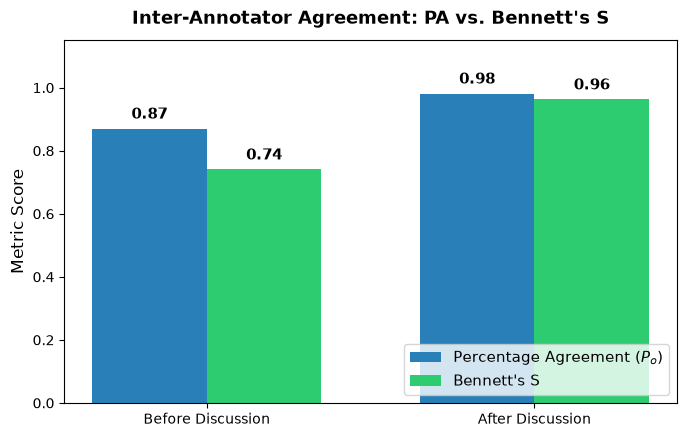

In [5]:
# Compute percentage agreement
before_pa = sum(df["before_group1_annotator1"] == df["before_group1_annotator2"]) / df.shape[0]
after_pa = sum(df["after_group1_annotator1"] == df["after_group1_annotator2"]) / df.shape[0]

# Chance-corrected agreement metric: Bennett, Alpert, and Goldstein’s S
# Computed using irrCAC's Brennan-Prediger method (bp), where for k=2 categories: S = 2*Po - 1
cac_before = CAC(df[["before_group1_annotator1", "before_group1_annotator2"]])
cac_after = CAC(df[["after_group1_annotator1", "after_group1_annotator2"]])

before_s = cac_before.bp()["est"]["coefficient_value"]
after_s = cac_after.bp()["est"]["coefficient_value"]

# Direct formula check: S = 2 * Po - 1
assert np.isclose(before_s, 2 * before_pa - 1), "Bennett's S formula check failed for before discussion!"
assert np.isclose(after_s, 2 * after_pa - 1), "Bennett's S formula check failed for after discussion!"

print(f"Percentage Agreement (Po) Before: {before_pa:.4f} ({before_pa:.2%}) | Bennett's S Before: {before_s:.4f}")
print(f"Percentage Agreement (Po) After:  {after_pa:.4f} ({after_pa:.2%}) | Bennett's S After:  {after_s:.4f}")

# Overall Summary Table
df_overall_agreement = pd.DataFrame({
    "Stage": ["Before Discussion", "After Discussion"],
    "Observed Agreement (Po)": [f"{before_pa:.2%}", f"{after_pa:.2%}"],
    "Bennett's S": [f"{before_s:.4f}", f"{after_s:.4f}"],
    "Absolute Gain": [f"{0.0:.2%}", f"+{after_pa - before_pa:.2%}"]
})
display(df_overall_agreement)

# Plot Percentage Agreement vs Bennett's S
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(2)
width = 0.35

bars_pa = ax.bar(x - width/2, [before_pa, after_pa], width, label="Percentage Agreement ($P_o$)", color="#2980b9")
bars_s = ax.bar(x + width/2, [before_s, after_s], width, label="Bennett's S", color="#2ecc71")

ax.set_ylabel("Metric Score")
ax.set_title("Inter-Annotator Agreement: PA vs. Bennett's S", fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(["Before Discussion", "After Discussion"])
ax.set_ylim(0, 1.15)
ax.legend(loc="lower right")

for bar in list(bars_pa) + list(bars_s):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0, height + 0.02, f"{height:.2f}", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

## 4. Per-Batch Analysis & Agreement Evolution
Granular evaluation across all 7 batches, tracking the annotator learning curve, discussions, expert escalations, and the dip in Batch 6 caused by ambiguous political critique tweets.

,Batch,N,Discussions,Escalated to Expert,Po (Before),Po (After),Bennett's S (Before),Bennett's S (After),Final Prevalence
0,Batch 1,12,2,0,83.33%,100.00%,0.6667,1.0000,16.67%
1,Batch 2,34,6,2,82.35%,94.12%,0.6471,0.8824,11.76%
2,Batch 3,34,4,1,88.24%,97.06%,0.7647,0.9412,5.88%
3,Batch 4,34,4,0,88.24%,100.00%,0.7647,1.0000,5.88%
4,Batch 5,34,2,0,94.12%,100.00%,0.8824,1.0000,8.82%
5,Batch 6,34,7,1,79.41%,97.06%,0.5882,0.9412,8.82%
6,Batch 7,34,3,0,91.18%,100.00%,0.8235,1.0000,5.88%


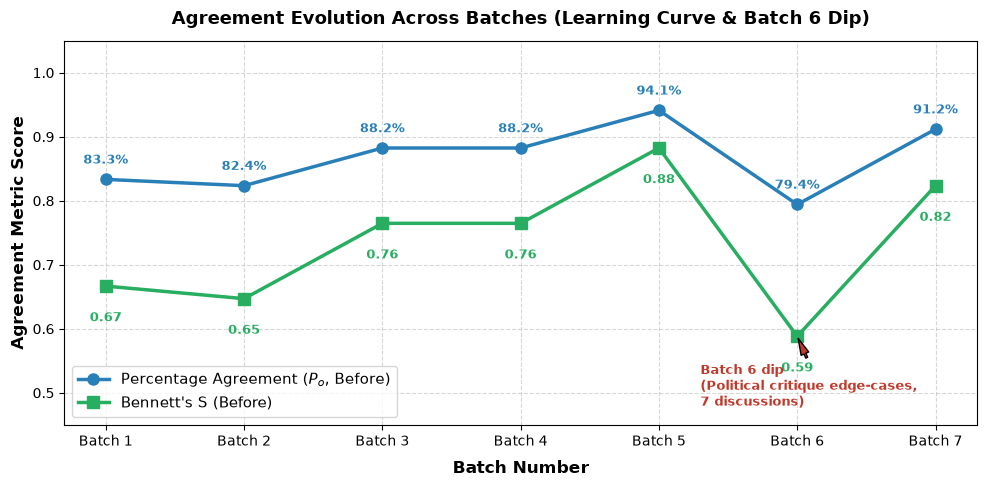

In [6]:
# Compute granular metrics per batch
batch_summary_list = []

for b in sorted(df["batch_number"].unique()):
    sub_b = df[df["batch_number"] == b]
    n_b = len(sub_b)
    
    # Discussions and expert escalations in this batch
    dis_b_before = int(sum(sub_b["before_group1_annotator1"] != sub_b["before_group1_annotator2"]))
    unresolved_b = int(sum(sub_b["after_group1_annotator1"] != sub_b["after_group1_annotator2"]))
    
    # Agreement metrics
    pa_b_before = (sub_b["before_group1_annotator1"] == sub_b["before_group1_annotator2"]).mean()
    pa_b_after = (sub_b["after_group1_annotator1"] == sub_b["after_group1_annotator2"]).mean()
    s_b_before = 2.0 * pa_b_before - 1.0
    s_b_after = 2.0 * pa_b_after - 1.0
    
    # Final prevalence
    prev_final_b = sub_b["final_label"].mean()
    
    batch_summary_list.append({
        "Batch": f"Batch {b}",
        "N": n_b,
        "Discussions": dis_b_before,
        "Escalated to Expert": unresolved_b,
        "Po (Before)": f"{pa_b_before:.2%}",
        "Po (After)": f"{pa_b_after:.2%}",
        "Bennett's S (Before)": f"{s_b_before:.4f}",
        "Bennett's S (After)": f"{s_b_after:.4f}",
        "Final Prevalence": f"{prev_final_b:.2%}",
        # raw numeric values for plotting
        "_pa_before": pa_b_before,
        "_s_before": s_b_before,
        "_discussions": dis_b_before
    })

df_batch_summary = pd.DataFrame(batch_summary_list)
display(df_batch_summary.drop(columns=["_pa_before", "_s_before", "_discussions"]))

# Plot: Evolution of Inter-Annotator Agreement across Batches 1 to 7
fig, ax1 = plt.subplots(figsize=(10, 5))
batches_x = np.arange(len(batch_summary_list))
batch_labels = [r["Batch"] for r in batch_summary_list]

po_values = [r["_pa_before"] for r in batch_summary_list]
s_values = [r["_s_before"] for r in batch_summary_list]
disc_values = [r["_discussions"] for r in batch_summary_list]

# Line plots for Po and Bennett's S
line1 = ax1.plot(batches_x, po_values, marker="o", linewidth=2.5, markersize=8, color="#2980b9", label="Percentage Agreement ($P_o$, Before)")
line2 = ax1.plot(batches_x, s_values, marker="s", linewidth=2.5, markersize=8, color="#27ae60", label="Bennett's S (Before)")

ax1.set_xlabel("Batch Number", fontweight="bold", labelpad=8)
ax1.set_ylabel("Agreement Metric Score", fontweight="bold")
ax1.set_xticks(batches_x)
ax1.set_xticklabels(batch_labels)
ax1.set_ylim(0.45, 1.05)
ax1.grid(True, linestyle="--", alpha=0.5)

# Annotate points on the line plot
for i, (po, s) in enumerate(zip(po_values, s_values)):
    ax1.text(i, po + 0.02, f"{po:.1%}", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#2980b9")
    ax1.text(i, s - 0.04, f"{s:.2f}", ha="center", va="top", fontsize=9, fontweight="bold", color="#27ae60")

# Highlight Batch 6 dip with an annotation
ax1.annotate(
    "Batch 6 dip\n(Political critique edge-cases,\n7 discussions)",
    xy=(5, s_values[5]), xytext=(4.3, 0.48),
    arrowprops=dict(facecolor="#c0392b", shrink=0.08, width=1.5, headwidth=6),
    fontsize=9.5, fontweight="bold", color="#c0392b"
)

ax1.set_title("Agreement Evolution Across Batches (Learning Curve & Batch 6 Dip)", fontweight="bold", pad=12)
ax1.legend(loc="lower left")

plt.tight_layout()
plt.show()

## 5. Offensiveness Prevalence: Overall & by Topic
Evaluation of offensiveness prevalence in the dataset before discussion (annotator average) versus after expert adjudication (final ground truth).

Overall Offensiveness Prevalence (Before Discussion Avg): 10.65%
Overall Offensiveness Prevalence (Final Ground Truth):    8.33% (18 / 216 tweets)


,Topic,Total Tweets (N),Prevalence (Before Avg),Final Offensive Count,Final Prevalence
0,BLM,78,4.49%,1 / 78,1.28%
1,Covid-19,63,11.11%,6 / 63,9.52%
2,Elections2020,75,16.67%,11 / 75,14.67%


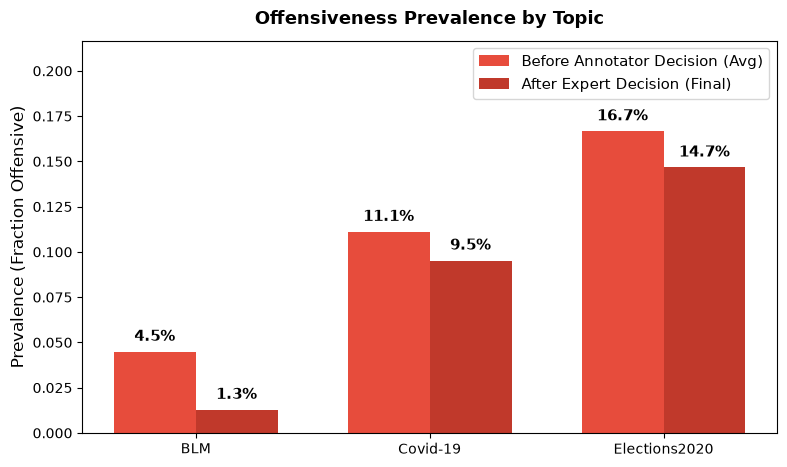

In [7]:
# Overall Ground Truth Prevalence
total_final_offensive = int(df["final_label"].sum())
overall_final_prev = df["final_label"].mean()
overall_before_prev = (df["before_group1_annotator1"].mean() + df["before_group1_annotator2"].mean()) / 2.0

print(f"Overall Offensiveness Prevalence (Before Discussion Avg): {overall_before_prev:.2%}")
print(f"Overall Offensiveness Prevalence (Final Ground Truth):    {overall_final_prev:.2%} ({total_final_offensive} / {n} tweets)")

# Extract topic from tweet text prefix
def get_topic(text):
    if "[Covid-19]" in text:
        return "Covid-19"
    elif "[Elections2020]" in text:
        return "Elections2020"
    elif "[BLM]" in text:
        return "BLM"
    return "Other"

df["topic"] = df["text"].apply(get_topic)

# Topic Prevalence Summary Table
topics = ["BLM", "Covid-19", "Elections2020"]
topic_summary = []
prev_before = []
prev_expert = []

for t in topics:
    sub = df[df["topic"] == t]
    p_b = (sub["before_group1_annotator1"].mean() + sub["before_group1_annotator2"].mean()) / 2.0
    p_e = sub["final_label"].mean()
    n_t = len(sub)
    n_off_final = int(sub["final_label"].sum())
    
    prev_before.append(p_b)
    prev_expert.append(p_e)
    topic_summary.append({
        "Topic": t,
        "Total Tweets (N)": n_t,
        "Prevalence (Before Avg)": f"{p_b:.2%}",
        "Final Offensive Count": f"{n_off_final} / {n_t}",
        "Final Prevalence": f"{p_e:.2%}"
    })

display(pd.DataFrame(topic_summary))

# Plot Offensiveness Prevalence by Topic
x = np.arange(len(topics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4.8))
bars_b = ax.bar(x - width/2, prev_before, width, label="Before Annotator Decision (Avg)", color="#e74c3c")
bars_e = ax.bar(x + width/2, prev_expert, width, label="After Expert Decision (Final)", color="#c0392b")

ax.set_ylabel("Prevalence (Fraction Offensive)")
ax.set_title("Offensiveness Prevalence by Topic", fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(topics)
y_max = max(max(prev_before), max(prev_expert))
ax.set_ylim(0, y_max * 1.30)
ax.legend(loc="upper right")

for bar in list(bars_b) + list(bars_e):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0, height + 0.004, f"{height:.1%}", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()